# Amortized methods in geostatistics

In [1]:
import matplotlib
import matplotlib.pyplot as plt

import numpy as np

import random
from tqdm import tqdm
import time

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import torch_geometric
from torch_geometric.data import Data
from torch_geometric.nn import global_mean_pool

from torch_geometric.data import Dataset
from torch_geometric.loader import DataLoader
from torch_geometric.data import Batch

from torch_geometric.utils import to_scipy_sparse_matrix
from torch_geometric.nn.conv import MessagePassing
from torch_geometric.utils import scatter
from torch_geometric.nn import aggr

/home/aloret/PycharmProjects/Neural_ST_inference/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
from scipy.sparse.csgraph import connected_components
from scipy.spatial import cKDTree
from scipy.optimize import minimize
import scipy.linalg as linalg

In [4]:
import gstlearn as gl
import gstlearn.plot as gp
import gstlearn.document as gdoc
gdoc.setNoScroll()

<IPython.core.display.Javascript object>

In [5]:
device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")

## Simulation

### Sampling

In [6]:
def sampling_matern(lambdaParent,lambdaDaughter,radiusCluster):

    xMin = 0
    xMax = 1
    yMin = 0
    yMax = 1

    rExt = radiusCluster  
    xMinExt = xMin - rExt
    xMaxExt = xMax + rExt
    yMinExt = yMin - rExt
    yMaxExt = yMax + rExt

    xDeltaExt = xMaxExt - xMinExt
    yDeltaExt = yMaxExt - yMinExt
    areaTotalExt = xDeltaExt * yDeltaExt  

    numbPointsParent = np.random.poisson(areaTotalExt * lambdaParent)  
    
    xxParent = xMinExt + xDeltaExt * np.random.uniform(0, 1, numbPointsParent)
    yyParent = yMinExt + yDeltaExt * np.random.uniform(0, 1, numbPointsParent)

    numbPointsDaughter = np.random.poisson(lambdaDaughter, numbPointsParent) 
    numbPoints = sum(numbPointsDaughter)

    theta = 2 * np.pi * np.random.uniform(0, 1, numbPoints) 
    rho = radiusCluster * np.sqrt(np.random.uniform(0, 1, numbPoints)) 
    xx0 = rho * np.cos(theta)
    yy0 = rho * np.sin(theta)

    xx = np.repeat(xxParent, numbPointsDaughter)
    yy = np.repeat(yyParent, numbPointsDaughter)

    xx = xx + xx0
    yy = yy + yy0

    booleInside = ((xx >= xMin) & (xx <= xMax) & (yy >= yMin) & (yy <= yMax))
    xx = xx[booleInside]
    yy = yy[booleInside]

    # data = {'x1': xx, 'x2': yy}
    # sample = pd.DataFrame(data)

    sample = gl.Db()
    sample.addColumns(xx,"x1")
    sample.addColumns(yy,"x2")
    sample.setLocators(["x1","x2"],gl.ELoc.X)

    return sample


def grid():

    sample = gl.Db()
    sample.addColumns(np.repeat(np.linspace(0,1,100),100),"x1")
    sample.addColumns(np.tile(np.linspace(0,1,100),100),"x2")
    sample.setLocators(["x1","x2"],gl.ELoc.X)

    return sample 

theta_size = 2

In [7]:
def simulation_matern(sample, theta_range, theta_std, plot=False):

    model = gl.Model.createFromParam(type=gl.ECov.MATERN, range = theta_range*np.sqrt(8), param = 1, sill = theta_std**2)  # range is the practical range of Matérn with smoothness parameter = 1
    err = gl.simtub(None, sample, model, None, nbsimu=1, seed=0, nbtuba = 1000)

    if plot:
            fig, axs = plt.subplots(1, 1, figsize=(7, 7), constrained_layout=True)

            axs.scatter(sample['x1'], sample['x2'], c=sample['Simu'], s=8) 
        
            axs.set_xlabel('x1')
            axs.set_ylabel('x2')
            axs.set_title('Simu Values with Selected Points')

            axs.set_xlim([0, 1])
            axs.set_ylim([0, 1])
            axs.axis('equal')

            plt.show()

    return sample

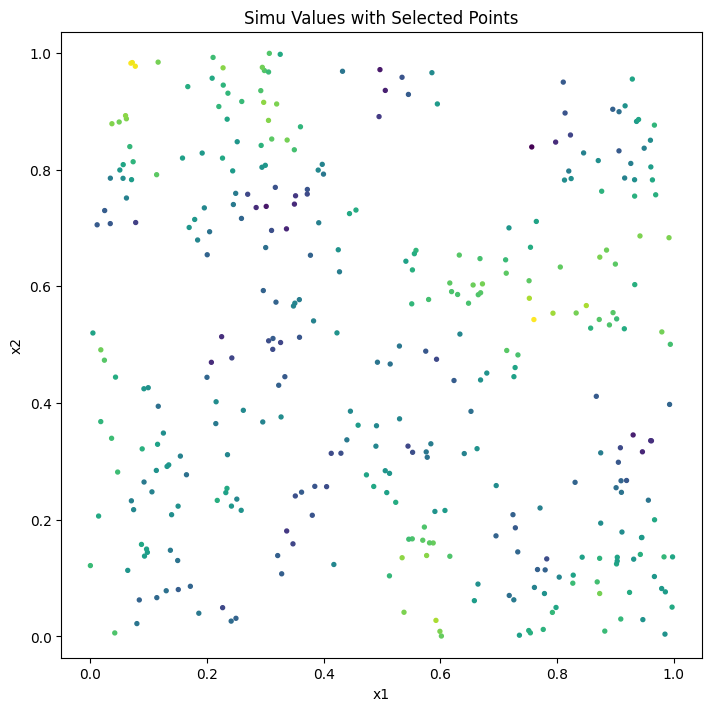


Data Base Characteristics

Data Base Summary
-----------------
File is organized as a set of isolated points
Space dimension              = 2
Number of Columns            = 3
Total number of samples      = 357

Variables
---------
Column = 0 - Name = x1 - Locator = x1
Column = 1 - Name = x2 - Locator = x2
Column = 2 - Name = Simu - Locator = z1

In [8]:
sample = sampling_matern(60,500//60,.1)
theta_range, theta_std = .1, 1.
simulation_matern(sample, theta_range, theta_std, plot=True)

In [9]:
def datamaker(constant_product, n, as_grid=False, range_min=.05, range_max=.5,std_min=.1, std_max=1.,lambdaParent_min=10,lambdaParent_max=60,radiusCluster = 0.15,log=False):

    datalist=[]

    range_list = np.random.uniform(range_min,range_max,n)
    std_list = np.random.uniform(std_min, std_max,n)
    lambdaParent = np.random.uniform(lambdaParent_min, lambdaParent_max,n)
    lambdaDaughter = constant_product / lambdaParent

    t = tqdm(range(0, n),total=n)

    for i in t:

        if as_grid :
            sample = grid() 
        else :
            sample = sampling_matern(lambdaParent[i],lambdaDaughter[i],radiusCluster)
        simu = simulation_matern(sample, range_list[i], std_list[i])

        theta = (range_list[i], std_list[i])

        datalist.append((simu,theta))

    return datalist

In [10]:
def baseline_mae(dataset):
    all_thetas = torch.stack([data[1] for data in dataset.datalist])
    
    theta_mean = all_thetas.mean(dim=0) 
    
    preds = theta_mean.unsqueeze(0).repeat(len(dataset), 1)
    
    mae = torch.mean(torch.abs(preds - all_thetas),dim=0)

    return mae, theta_mean

### Grid

In [11]:
def points_to_grid(sample, nb_bins=100):
    
    bin_size = 1.0 / nb_bins

    x1 = torch.tensor(sample['x1'], dtype=torch.float32)
    x2 = torch.tensor(sample['x2'], dtype=torch.float32)
    values = torch.tensor(sample['Simu'], dtype=torch.float32)
    
    ix = torch.clamp((x1 / bin_size).long(), max=nb_bins - 1)
    iy = torch.clamp((x2 / bin_size).long(), max=nb_bins - 1)

    flat_idx = ix * nb_bins + iy
    
    # value_flat = torch.zeros(nb_bins * nb_bins, dtype=torch.float32)
    # count_flat = torch.zeros(nb_bins * nb_bins, dtype=torch.float32)
        
    # value_flat.index_add_(0, flat_idx, values)
    # count_flat.index_add_(0, flat_idx, torch.ones_like(values))

    # mean_grid = torch.empty_like(value_flat)
    # mean_grid[:] = float('nan')
    # mask = count_flat > 0
    # mean_grid[mask] = value_flat[mask] / count_flat[mask]

    # return mean_grid.view(nb_bins, nb_bins)

    value_flat = torch.full((nb_bins * nb_bins,), float('nan'))

    unique_idx = flat_idx.unique()
    for idx in unique_idx:
        indices_in_cell = torch.where(flat_idx == idx)[0]
        chosen = indices_in_cell[torch.randint(0, len(indices_in_cell), (1,))]
        value_flat[idx] = values[chosen]

    return value_flat.view(nb_bins, nb_bins)

In [12]:
class GridMaskSetDataset(Dataset):
    def __init__(self, datalist):
        self.datalist = datalist

    def __len__(self):
        return len(self.datalist)

    def __getitem__(self, idx):
                
        data = self.datalist[idx][0]
        mask = (~torch.isnan(data)).float()
        
        data = torch.nan_to_num(data, nan=0.)
        
        data = torch.stack([data, mask], dim=0) 
        
        theta = self.datalist[idx][1]
        
        return data, theta


class GridFullSetDataset(Dataset):
    def __init__(self, datalist):
        self.datalist = datalist

    def __len__(self):
        return len(self.datalist)

    def __getitem__(self, idx):
                
        data = self.datalist[idx][0]
        mask = (~torch.isnan(data)).float()
        
        data = torch.nan_to_num(data, nan=0.)
        
        data = data.unsqueeze(0)
        
        theta = self.datalist[idx][1]
        
        return data, theta

In [13]:
def datamaker_grid(simu,bins = 100, mask=True):

    n = len(simu)
    datalist = []
    
    t = tqdm(range(0, n),total=n)
    
    for i in t:

        data = points_to_grid(simu[i][0], bins)
        theta = torch.tensor(simu[i][1])
        
        datalist.append((data, theta))               

    if mask :
        return GridMaskSetDataset(datalist)
    else : 
        return GridFullSetDataset(datalist)

## CNN

In [14]:
class CNN_network(nn.Module):
    def __init__(self, in_channels=2, hidden=32, out_dim=2):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, hidden, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden, hidden, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden, hidden, 3, padding=1),
            nn.ReLU(),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)  # ~vec(·) 
        self.dense = nn.Sequential(
            nn.Linear(hidden, 64),
            nn.ReLU(),
            nn.Linear(64, out_dim)  
        )

        # self.lin = nn.Linear(hidden, 64)

        # self.head1 = nn.Linear(64, 1)
        # self.head2 = nn.Sequential(
        #     nn.Dropout(0.3),  
        #     nn.Linear(64, 1)
        # )

    def forward(self, x):
        
        # shape : (batch size, 2 = data+mask, grid_h, grib_v)
        h = self.conv(x)
        # shape : (batch size, hidden, grid_h, grib_v)
        h = self.pool(h).view(h.shape[0], -1)
        
        # shape : (batch size, 2 = data+mask)
        out = self.dense(h)

        # out = self.lin(h)
        
        # out1 = self.head1(out)
        # out2 = self.head2(out)

        # out = torch.cat([out1, out2], dim=1)

        
        # shape : (batch size, 2 = theta)
        
        return out

class CNN_network_nodense(nn.Module):
    def __init__(self, in_channels=2, hidden=32, out_dim=2):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, hidden, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden, hidden, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden, hidden, 3, padding=1),
            nn.ReLU(),
        )
        self.pool = nn.AdaptiveAvgPool2d(16)
        self.conv_out = nn.Sequential(
            nn.Conv2d(hidden, hidden//2, 4, padding=0,stride=4),
            nn.ReLU(),
            nn.Conv2d(hidden//2, 2, 4, padding=0,stride=4)
        )

    def forward(self, x):
        
        h = self.conv(x)
        
        out = self.pool(h)
        out = self.conv_out(out)
        out = out.view(h.shape[0], -1)
        
        return out


# class CNN_network_partial(nn.Module):
#     def __init__(self, in_channels=2, out_channels=2, hidden=16):
#         super().__init__()
#         self.input_conv = nn.Conv2d(1, 1, kernel_size=4)
#         torch.nn.init.kaiming_normal_(self.input_conv.weight)
#         self.slide_winsize = self.input_conv.weight.numel() / in_channels

#         self.conv = nn.Sequential(
#             nn.Conv2d(in_channels, hidden, 3, padding=1),
#             nn.ReLU(),
#             nn.Conv2d(hidden, hidden, 3, padding=1),
#             nn.ReLU(),
#             nn.Conv2d(hidden, hidden, 3, padding=1),
#             nn.ReLU(),
#         )
#         self.pool = nn.AdaptiveAvgPool2d(16)
#         self.conv_out = nn.Sequential(
#             nn.Conv2d(hidden, hidden//2, 4, padding=0,stride=4),
#             nn.ReLU(),
#             nn.Conv2d(hidden//2, 2, 4, padding=0,stride=4)
#         )

#     def forward(self, x):

#         x, mask = x[:,0].unsqueeze(1), x[:,1].unsqueeze(1)

#         ###
                
#         with torch.no_grad():
#             mask_output1 = F.conv2d(mask, torch.ones_like(self.input_conv.weight), 
#                                    bias=None, stride=self.input_conv.stride, 
#                                    padding=self.input_conv.padding)

        
#         x1 = x * mask
#         x1 = self.input_conv(x1)

#         mask_ratio = self.slide_winsize / (mask_output1 + 1e-8)
#         x1 = x1 * mask_ratio

#         x1 = x1 * (mask_output1 > 0)
#         mask_output1 = (mask_output1 > 0).float()

#         ###

#         with torch.no_grad():
#             mask_output2 = F.conv2d(mask_output1, torch.ones_like(self.input_conv.weight), 
#                                    bias=None, stride=self.input_conv.stride, 
#                                    padding=self.input_conv.padding)

        
#         x2 = x1 * mask_output1
#         x2 = self.input_conv(x2)


#         mask_ratio = self.slide_winsize / (mask_output2 + 1e-8)
#         x2 = x2 * mask_ratio

#         x2 = x2 * (mask_output2 > 0)
#         mask_output2 = (mask_output2 > 0).float()
        
#         ###

#         out = torch.cat((x2, mask_output2),dim=1)

#         # print(out.shape)
        
#         out = self.conv(out)
        
#         out = self.pool(out)
#         out = self.conv_out(out)
#         out = out.view(out.shape[0], -1)
        
#         return out

In [15]:
def train_cnn(model, optimizer, loader):
    
    model.train()
    MAE = torch.nn.L1Loss(reduction="mean")
    
    # sum_loss = torch.zeros(theta_size)
    sum_loss = torch.zeros((n_train,theta_size))

    for i, (x, theta) in enumerate(loader):
        optimizer.zero_grad()

        x, theta = x.to(device), theta.to(device)

        output = model(x)
        
        batch_loss = MAE(output, theta)
        
        batch_loss.backward()
        optimizer.step()

        # sum_loss += torch.mean(torch.abs(output - theta),dim=0)
        sum_loss[i*len(theta):(i+1)*len(theta)] = torch.abs(output - theta)

    return sum_loss # / len(loader)



## Data

In [16]:
n_points = 40 # 1000
n_train = 10 # 500
n_test = 2 # 100

batch_size = 2 # 20

In [17]:
sampling_train_mask = datamaker(n_points, n_train, as_grid=False)

dataset_grid_mask = datamaker_grid(sampling_train_mask, mask=True)
loader_grid_mask = DataLoader(dataset_grid_mask, batch_size, shuffle=True)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10/10 [00:00<00:00, 805.61it/s]


In [18]:
sampling_train_full = datamaker(n_points, n_train, as_grid=True)

dataset_grid_full = datamaker_grid(sampling_train_full, mask=False)
loader_grid_full = DataLoader(dataset_grid_full, batch_size, shuffle=True)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10/10 [00:03<00:00,  2.70it/s]


In [19]:
sampling_test_mask = datamaker(n_points, n_test, as_grid=False)

loader_grid_test_mask = DataLoader(datamaker_grid(sampling_test_mask, mask=True), 1, shuffle=False)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:00<00:00, 278.63it/s]


In [20]:
sampling_test_full = datamaker(n_points, n_test, as_grid=True)

loader_grid_test_full = DataLoader(datamaker_grid(sampling_test_full, mask=False), 1, shuffle=False)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:00<00:00,  2.70it/s]


In [21]:
n_epochs = 50 # 100

## Train model with dense layer

### With mask

Epoch 50/50: 100%|███████████████████████████████████████████████████████████████████████████████████████████████| 50/50 [00:04<00:00, 11.72it/s, loss=tensor([0.1010, 0.1811], grad_fn=<MeanBackward1>)]


Time to train : 4.27s


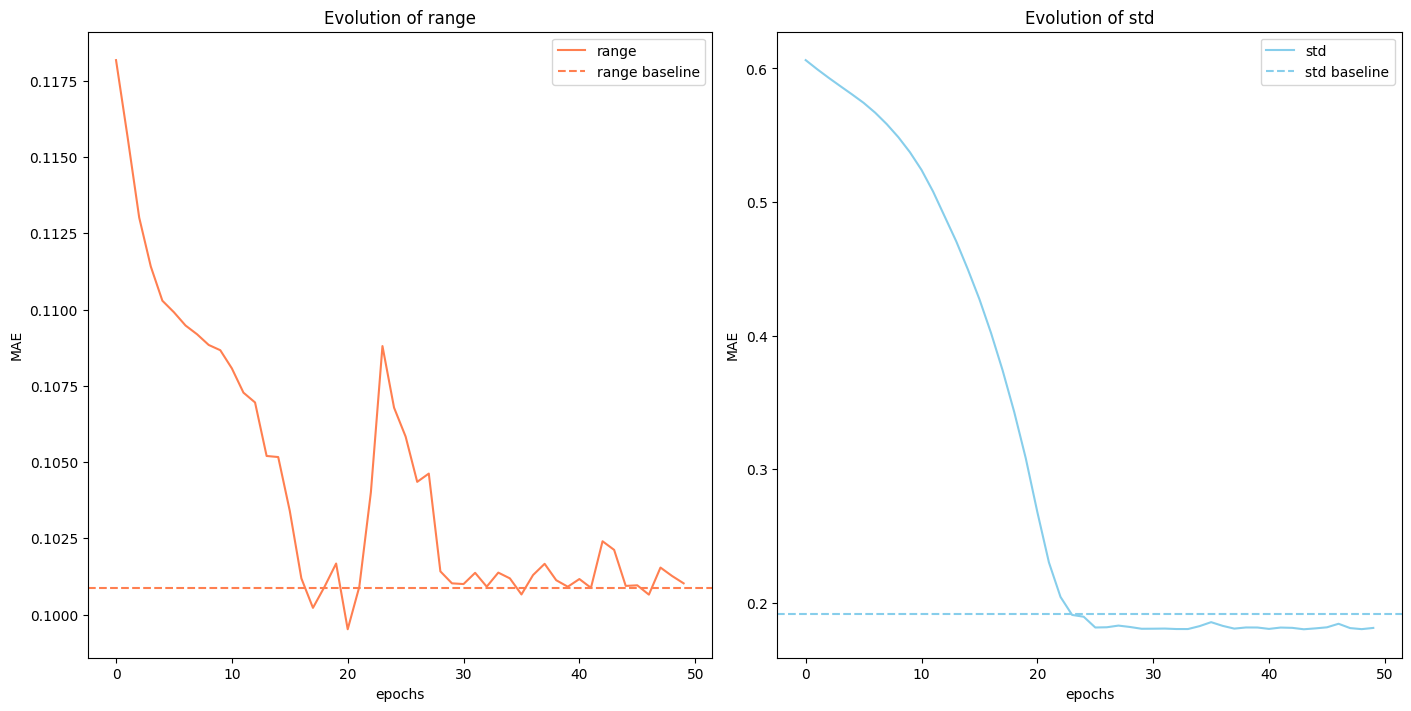

In [22]:
model_grid_mask = CNN_network(in_channels=2).to(device)
optimizer_grid = torch.optim.Adam(model_grid_mask.parameters(), lr=1e-4)

all_loss_train_mask = torch.zeros((n_epochs, n_train,theta_size))

t = tqdm(range(0, n_epochs),total=n_epochs)

time_train_mask = time.time()

for epoch in t:
    
    loss = train_cnn(
        model_grid_mask,
        optimizer_grid,
        loader_grid_mask,
    )

    t.set_description(f"Epoch {epoch+1}/{n_epochs}")
    t.set_postfix(loss=f"{loss.mean(dim=0)}")
    all_loss_train_mask[epoch] = loss


time_train_mask = time.time() - time_train_mask

print(f"Time to train : {time_train_mask:.2f}s")

all_loss_train_mask = all_loss_train_mask.detach().numpy()

fig_train_mask, ax = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)
ax[0].plot(all_loss_train_mask.mean(axis=1)[:,0], 'coral', label='range')
ax[1].plot(all_loss_train_mask.mean(axis=1)[:,1], 'skyblue',label='std')

based, _ = baseline_mae(dataset_grid_mask)
ax[0].axhline(based[0],color='coral', ls='--', label='range baseline')
plt.axhline(based[1],color='skyblue', ls='--', label='std baseline')

ax[0].set_title('Evolution of range')
ax[1].set_title('Evolution of std')
ax[0].set_xlabel('epochs')
ax[1].set_xlabel('epochs')
ax[0].set_ylabel('MAE')
ax[1].set_ylabel('MAE')
ax[0].legend()
ax[1].legend()

### Without mask

Epoch 50/50: 100%|███████████████████████████████████████████████████████████████████████████████████████████████| 50/50 [00:03<00:00, 12.53it/s, loss=tensor([0.1001, 0.0785], grad_fn=<MeanBackward1>)]

Time to train : 3.99s


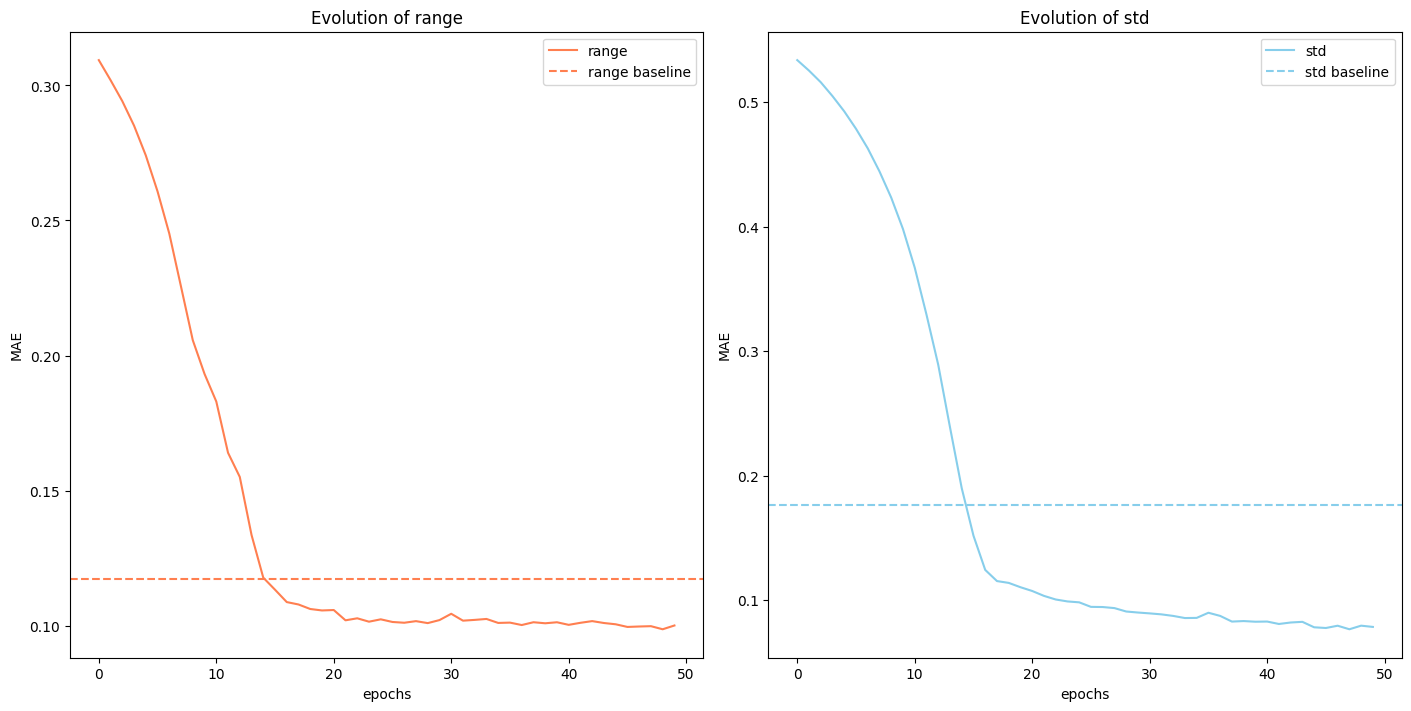

In [23]:
model_grid_full = CNN_network(in_channels=1).to(device)
optimizer_grid = torch.optim.Adam(model_grid_full.parameters(), lr=1e-4)

all_loss_train_full = torch.zeros((n_epochs, n_train,theta_size))

t = tqdm(range(0, n_epochs),total=n_epochs)

time_train_full = time.time()

for epoch in t:
    
    loss = train_cnn(
        model_grid_full,
        optimizer_grid,
        loader_grid_full,
    )

    t.set_description(f"Epoch {epoch+1}/{n_epochs}")
    t.set_postfix(loss=f"{loss.mean(dim=0)}")
    all_loss_train_full[epoch] = loss

time_train_full = time.time() - time_train_full

print(f"Time to train : {time_train_full:.2f}s")

all_loss_train_full = all_loss_train_full.detach().numpy()

fig_train_full, ax = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)
ax[0].plot(all_loss_train_full.mean(axis=1)[:,0], 'coral', label='range')
ax[1].plot(all_loss_train_full.mean(axis=1)[:,1], 'skyblue',label='std')

based, _ = baseline_mae(dataset_grid_full)
ax[0].axhline(based[0],color='coral', ls='--', label='range baseline')
plt.axhline(based[1],color='skyblue', ls='--', label='std baseline')

ax[0].set_title('Evolution of range')
ax[1].set_title('Evolution of std')
ax[0].set_xlabel('epochs')
ax[1].set_xlabel('epochs')
ax[0].set_ylabel('MAE')
ax[1].set_ylabel('MAE')
ax[0].legend()
ax[1].legend()

## Train model without dense layer

### With mask

Epoch 50/50: 100%|███████████████████████████████████████████████████████████████████████████████████████████████| 50/50 [00:04<00:00, 12.19it/s, loss=tensor([0.1008, 0.1785], grad_fn=<MeanBackward1>)]

Time to train : 4.10s


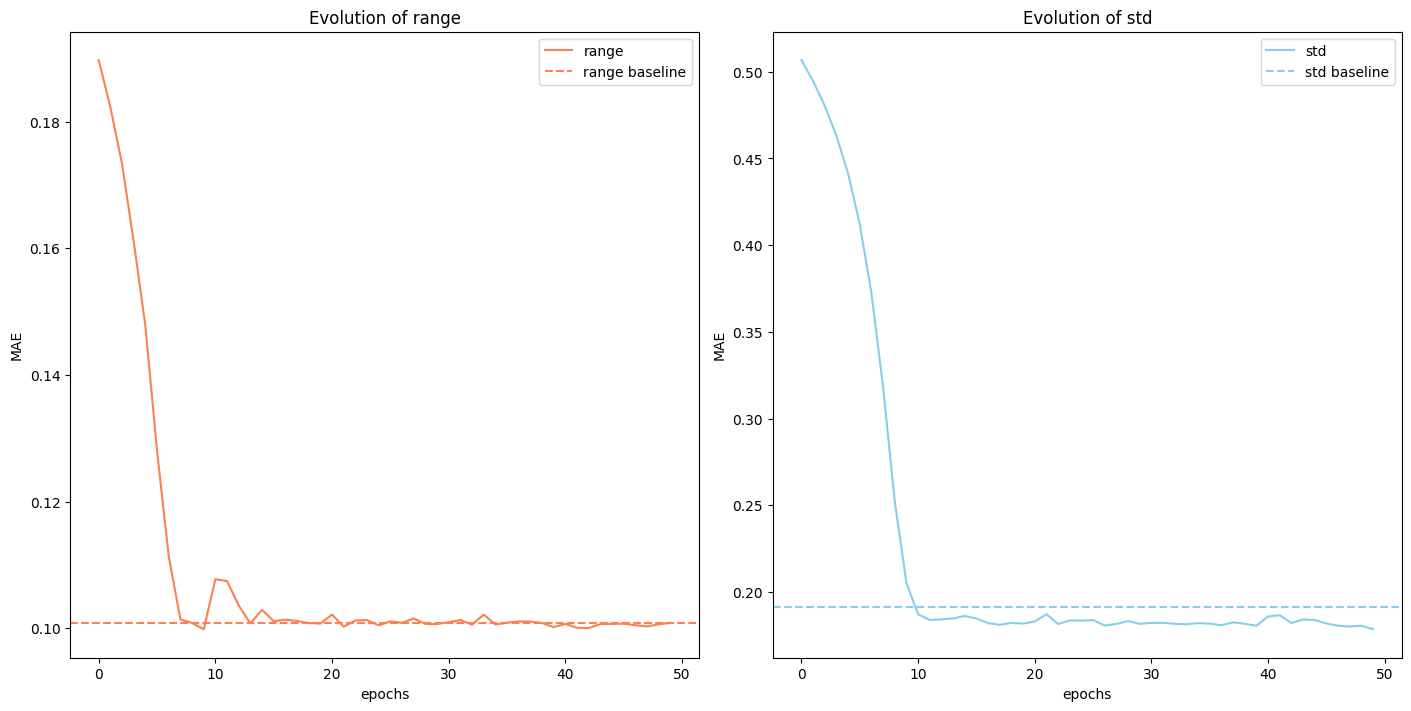

In [24]:
model_grid_nodense_mask = CNN_network_nodense(in_channels=2).to(device)
optimizer_grid = torch.optim.Adam(model_grid_nodense_mask.parameters(), lr=1e-4)

all_loss_train_nodense_mask = torch.zeros((n_epochs, n_train,theta_size))

t = tqdm(range(0, n_epochs),total=n_epochs)

time_train_nodense_mask = time.time()

for epoch in t:
    
    loss = train_cnn(
        model_grid_nodense_mask,
        optimizer_grid,
        loader_grid_mask,
    )

    t.set_description(f"Epoch {epoch+1}/{n_epochs}")
    t.set_postfix(loss=f"{loss.mean(dim=0)}")
    all_loss_train_nodense_mask[epoch] = loss

time_train_nodense_mask = time.time() - time_train_nodense_mask

print(f"Time to train : {time_train_nodense_mask:.2f}s")

all_loss_train_nodense_mask = all_loss_train_nodense_mask.detach().numpy()

fig_train_nodense_mask, ax = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)
ax[0].plot(all_loss_train_nodense_mask.mean(axis=1)[:,0], 'coral', label='range')
ax[1].plot(all_loss_train_nodense_mask.mean(axis=1)[:,1], 'skyblue',label='std')

based, _ = baseline_mae(dataset_grid_mask)
ax[0].axhline(based[0],color='coral', ls='--', label='range baseline')
plt.axhline(based[1],color='skyblue', ls='--', label='std baseline')

ax[0].set_title('Evolution of range')
ax[1].set_title('Evolution of std')
ax[0].set_xlabel('epochs')
ax[1].set_xlabel('epochs')
ax[0].set_ylabel('MAE')
ax[1].set_ylabel('MAE')
ax[0].legend()
ax[1].legend()

### Without mask

Epoch 50/50: 100%|███████████████████████████████████████████████████████████████████████████████████████████████| 50/50 [00:04<00:00, 11.65it/s, loss=tensor([0.0571, 0.0382], grad_fn=<MeanBackward1>)]

Time to train : 4.29s


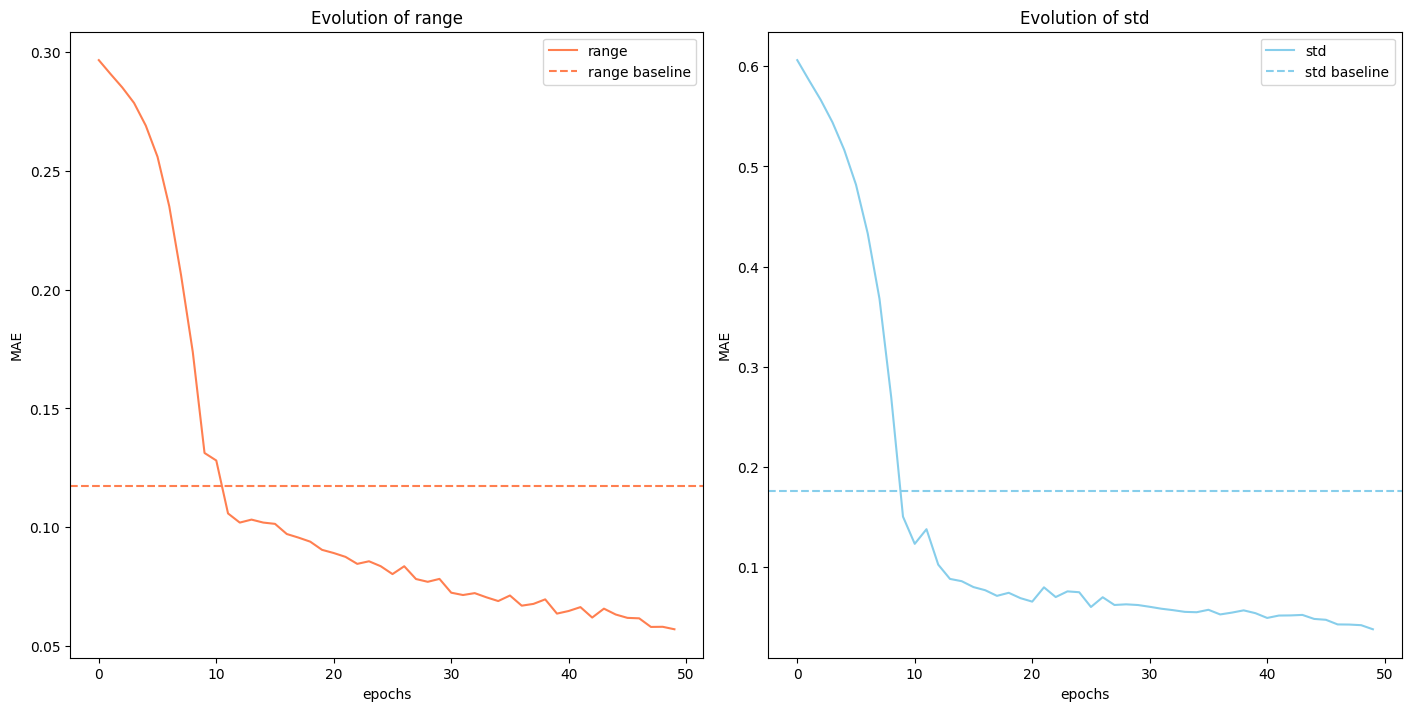

In [25]:
model_grid_nodense_full = CNN_network_nodense(in_channels=1).to(device)
optimizer_grid = torch.optim.Adam(model_grid_nodense_full.parameters(), lr=1e-4)

all_loss_train_nodense_full = torch.zeros((n_epochs, n_train,theta_size))

t = tqdm(range(0, n_epochs),total=n_epochs)

time_train_nodense_full = time.time()

for epoch in t:
    
    loss = train_cnn(
        model_grid_nodense_full,
        optimizer_grid,
        loader_grid_full,
    )

    t.set_description(f"Epoch {epoch+1}/{n_epochs}")
    t.set_postfix(loss=f"{loss.mean(dim=0)}")
    all_loss_train_nodense_full[epoch] = loss

time_train_nodense_full = time.time() - time_train_nodense_full

print(f"Time to train : {time_train_nodense_full:.2f}s")

all_loss_train_nodense_full= all_loss_train_nodense_full.detach().numpy()

fig_train_nodense_full, ax = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)
ax[0].plot(all_loss_train_nodense_full.mean(axis=1)[:,0], 'coral', label='range')
ax[1].plot(all_loss_train_nodense_full.mean(axis=1)[:,1], 'skyblue',label='std')

based, _ = baseline_mae(dataset_grid_full)
ax[0].axhline(based[0],color='coral', ls='--', label='range baseline')
plt.axhline(based[1],color='skyblue', ls='--', label='std baseline')

ax[0].set_title('Evolution of range')
ax[1].set_title('Evolution of std')
ax[0].set_xlabel('epochs')
ax[1].set_xlabel('epochs')
ax[0].set_ylabel('MAE')
ax[1].set_ylabel('MAE')
ax[0].legend()
ax[1].legend()

## Train partial CNN model

### Without Mask

## Tests

In [26]:
all_loss_test_mask = torch.zeros(n_test,theta_size)

time_test_grid_mask = time.time()

for i, (data_test, theta_test) in enumerate(loader_grid_test_mask) : 
    
    output = model_grid_mask(data_test)

    all_loss_test_mask[i] = torch.abs(output - theta_test)[0]


time_test_grid_mask = time.time() - time_test_grid_mask
print(f"\nTime to test : {time_test_grid_mask:.2f}s")

all_loss_test_mask = all_loss_test_mask.detach().numpy()
print("Test loss :", np.mean(all_loss_test_mask,axis=0), "±", np.std(all_loss_test_mask,axis=0))


Time to test : 0.01s
Test loss : [0.12987997 0.39037734] ± [0.09809288 0.04017465]


In [27]:
all_loss_test_full = torch.zeros(n_test,theta_size)

time_test_grid_full = time.time()

for i, (data_test, theta_test) in enumerate(loader_grid_test_full) : 
    
    output = model_grid_full(data_test)

    all_loss_test_full[i] = torch.abs(output - theta_test)[0]


time_test_grid_full = time.time() - time_test_grid_full
print(f"\nTime to test : {time_test_grid_full:.2f}s")

all_loss_test_full = all_loss_test_full.detach().numpy()
print("Test loss :", np.mean(all_loss_test_full,axis=0), "±", np.std(all_loss_test_full,axis=0))


Time to test : 0.01s
Test loss : [0.04072092 0.17475751] ± [0.02535226 0.13016331]


In [28]:
all_loss_test_nodense_mask = torch.zeros(n_test,theta_size)

time_test_grid_nodense_mask = time.time()

for i, (data_test, theta_test) in enumerate(loader_grid_test_mask) : 
    
    output = model_grid_nodense_mask(data_test)

    all_loss_test_nodense_mask[i] = torch.abs(output - theta_test)[0]


time_test_grid_nodense_mask = time.time() - time_test_grid_nodense_mask
print(f"\nTime to test : {time_test_grid_nodense_mask:.2f}s")

all_loss_test_nodense_mask = all_loss_test_nodense_mask.detach().numpy()
print("Test loss :", np.mean(all_loss_test_nodense_mask,axis=0), "±", np.std(all_loss_test_nodense_mask,axis=0))


Time to test : 0.01s
Test loss : [0.12396901 0.39016503] ± [0.09658626 0.03328569]


In [29]:
all_loss_test_nodense_full = torch.zeros(n_test,theta_size)

time_test_grid_nodense_full = time.time()

for i, (data_test, theta_test) in enumerate(loader_grid_test_full) : 
    
    output = model_grid_nodense_full(data_test)

    all_loss_test_nodense_full[i] = torch.abs(output - theta_test)[0]


time_test_grid_nodense_full = time.time() - time_test_grid_nodense_full
print(f"\nTime to test : {time_test_grid_nodense_full:.2f}s")

all_loss_test_nodense_full = all_loss_test_nodense_full.detach().numpy()
print("Test loss :", np.mean(all_loss_test_nodense_full,axis=0), "±", np.std(all_loss_test_nodense_full,axis=0))


Time to test : 0.01s
Test loss : [0.09583919 0.23098487] ± [0.00761644 0.12307811]


## Conclusion Mask

/tmp/ipykernel_2532909/851429451.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[0].boxplot(loss_range, labels=methods, patch_artist=True,
/tmp/ipykernel_2532909/851429451.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[1].boxplot(loss_std, labels=methods, patch_artist=True,


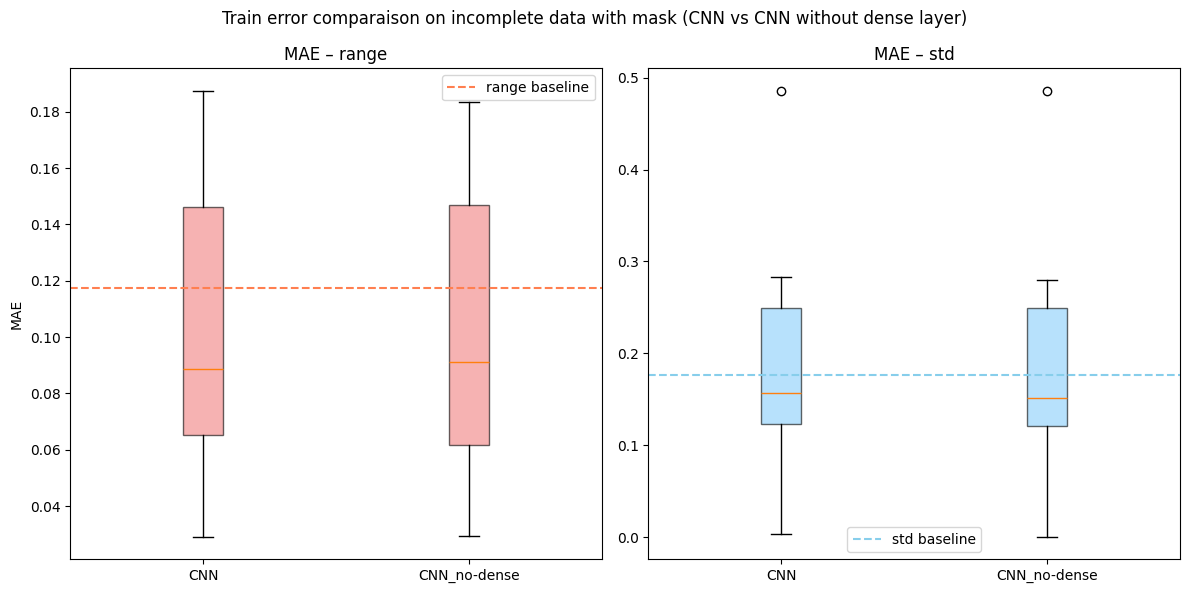

In [30]:
methods = ['CNN', 'CNN_no-dense']

loss_range = [
    all_loss_train_mask[-1, :, 0],
    all_loss_train_nodense_mask[-1,:, 0],
]

loss_std = [
    all_loss_train_mask[-1,:, 1],
    all_loss_train_nodense_mask[-1,:, 1],
]

### Boxplot
fig_box_train_mask, axs = plt.subplots(1, 2, figsize=(12, 6))

axs[0].boxplot(loss_range, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='lightcoral', alpha=0.6))
axs[0].set_title("MAE – range")
axs[0].set_ylabel("MAE")

axs[1].boxplot(loss_std, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='lightskyblue', alpha=0.6))
axs[1].set_title("MAE – std")

axs[0].axhline(based[0],color='coral', ls='--', label='range baseline')
axs[1].axhline(based[1],color='skyblue', ls='--', label='std baseline')

axs[0].legend()
axs[1].legend()

plt.suptitle("Train error comparaison on incomplete data with mask (CNN vs CNN without dense layer)")
plt.tight_layout()
plt.show()




/tmp/ipykernel_2532909/286724988.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[0].boxplot(loss_range, labels=methods, patch_artist=True,
/tmp/ipykernel_2532909/286724988.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[1].boxplot(loss_std, labels=methods, patch_artist=True,


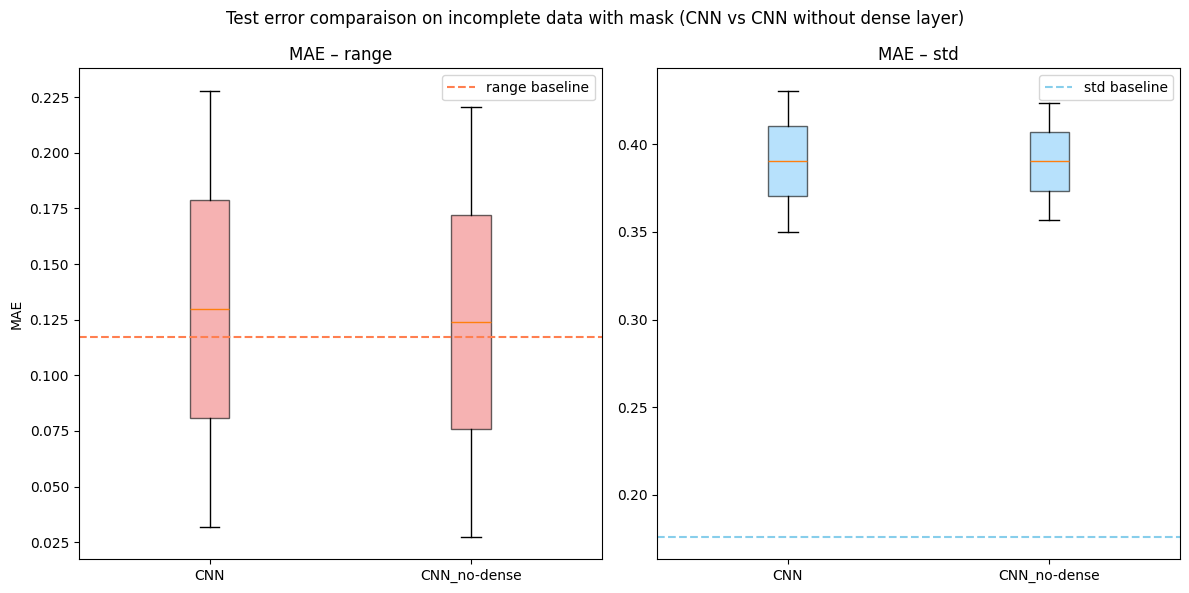

In [31]:
methods = ['CNN', 'CNN_no-dense']

loss_range = [
    all_loss_test_mask[:, 0],
    all_loss_test_nodense_mask[:, 0],
]

loss_std = [
    all_loss_test_mask[:, 1],
    all_loss_test_nodense_mask[:, 1],
]

### Boxplot
fig_box_test_mask, axs = plt.subplots(1, 2, figsize=(12, 6))

axs[0].boxplot(loss_range, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='lightcoral', alpha=0.6))
axs[0].set_title("MAE – range")
axs[0].set_ylabel("MAE")

axs[1].boxplot(loss_std, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='lightskyblue', alpha=0.6))
axs[1].set_title("MAE – std")

axs[0].axhline(based[0],color='coral', ls='--', label='range baseline')
axs[1].axhline(based[1],color='skyblue', ls='--', label='std baseline')

axs[0].legend()
axs[1].legend()

plt.suptitle("Test error comparaison on incomplete data with mask (CNN vs CNN without dense layer)")
plt.tight_layout()
plt.show()




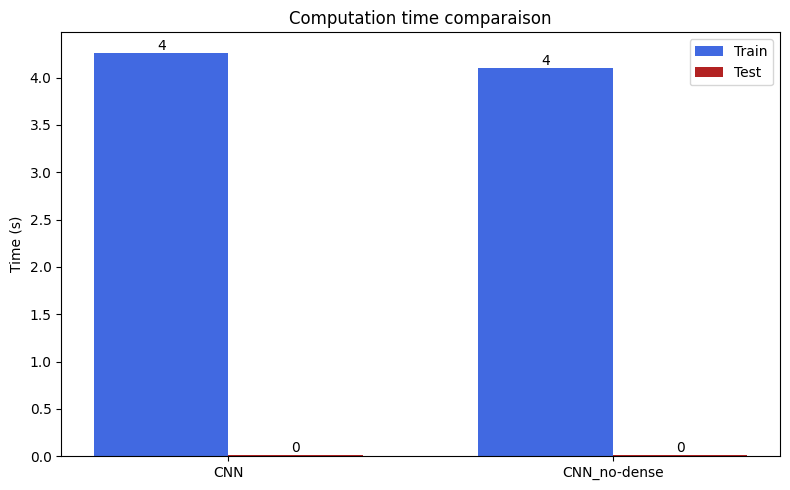

<Figure size 640x480 with 0 Axes>

In [32]:
### Time
train_times = [time_train_mask, time_train_nodense_mask] 
test_times = [time_test_grid_mask, time_test_grid_nodense_mask]

x = np.arange(len(methods))
width = 0.35

fig_time_mask, ax = plt.subplots(figsize=(8, 5))
bar1 = ax.bar(x - width/2, train_times, width, label='Train', color='royalblue')
bar2 = ax.bar(x + width/2, test_times, width, label='Test', color='firebrick')

for rect in bar1 + bar2:
    height = rect.get_height()
    plt.text(rect.get_x() + rect.get_width() / 2.0, height, f'{height:.0f}', ha='center', va='bottom')

ax.set_xticks(x)
ax.set_xticklabels(methods)
ax.set_ylabel("Time (s)")
ax.set_title("Computation time comparaison")
ax.legend()

plt.tight_layout()
plt.show()

plt.savefig("myImagePDF.pdf", format="pdf", bbox_inches="tight")

## Conclusion No Mask

/tmp/ipykernel_2532909/2652110687.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[0].boxplot(loss_range, labels=methods, patch_artist=True,
/tmp/ipykernel_2532909/2652110687.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[1].boxplot(loss_std, labels=methods, patch_artist=True,


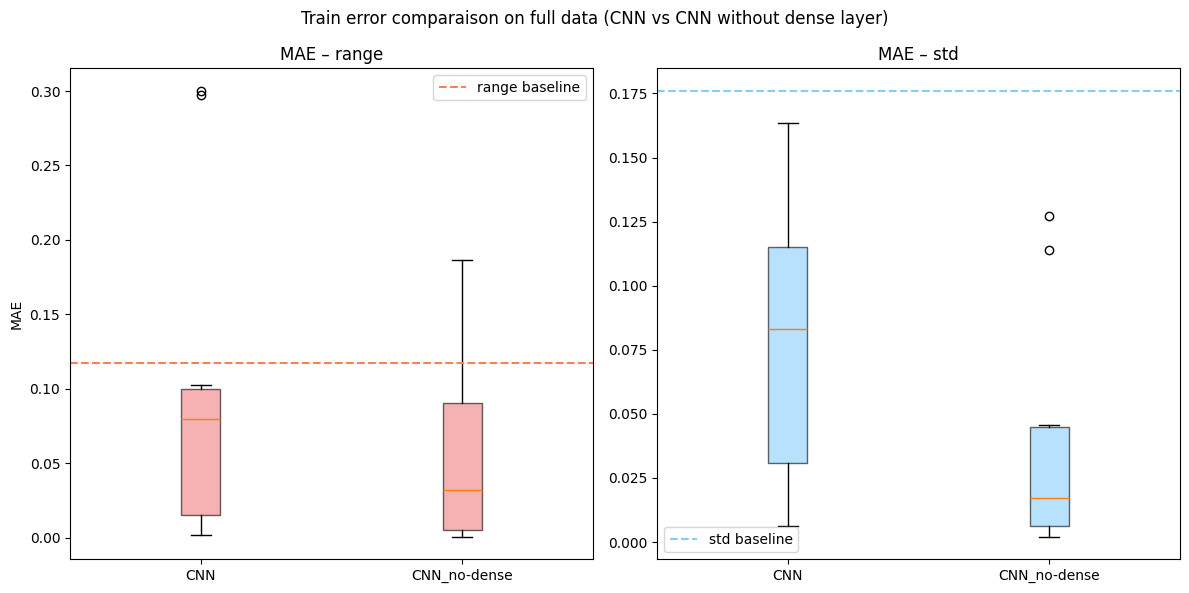

In [33]:
methods = ['CNN', 'CNN_no-dense']

loss_range = [
    all_loss_train_full[-1, :, 0],
    all_loss_train_nodense_full[-1, :, 0],
]

loss_std = [
    all_loss_train_full[-1, :, 1],
    all_loss_train_nodense_full[-1, :, 1],
]

### Boxplot
fig_box_train_full, axs = plt.subplots(1, 2, figsize=(12, 6))

axs[0].boxplot(loss_range, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='lightcoral', alpha=0.6))
axs[0].set_title("MAE – range")
axs[0].set_ylabel("MAE")

axs[1].boxplot(loss_std, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='lightskyblue', alpha=0.6))
axs[1].set_title("MAE – std")

axs[0].axhline(based[0],color='coral', ls='--', label='range baseline')
axs[1].axhline(based[1],color='skyblue', ls='--', label='std baseline')

axs[0].legend()
axs[1].legend()

plt.suptitle("Train error comparaison on full data (CNN vs CNN without dense layer)")
plt.tight_layout()
plt.show()


/tmp/ipykernel_2532909/86735602.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[0].boxplot(loss_range, labels=methods, patch_artist=True,
/tmp/ipykernel_2532909/86735602.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[1].boxplot(loss_std, labels=methods, patch_artist=True,


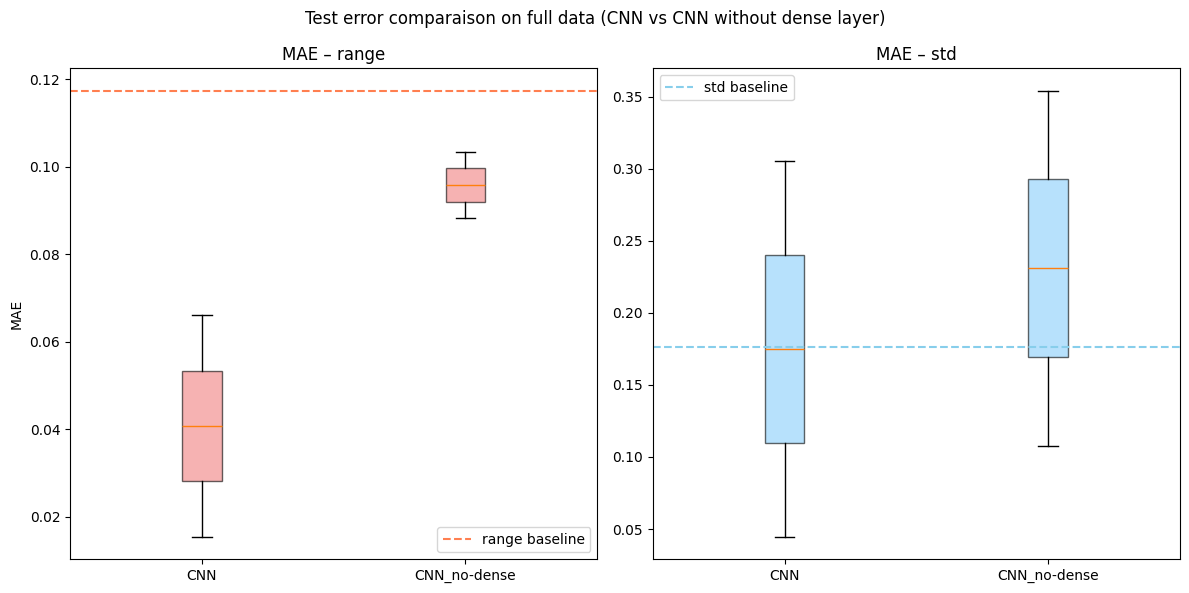

In [34]:
methods = ['CNN', 'CNN_no-dense']

loss_range = [
    all_loss_test_full[:, 0],
    all_loss_test_nodense_full[:, 0],
]

loss_std = [
    all_loss_test_full[:, 1],
    all_loss_test_nodense_full[:, 1],
]

### Boxplot
fig_box_test_full, axs = plt.subplots(1, 2, figsize=(12, 6))

axs[0].boxplot(loss_range, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='lightcoral', alpha=0.6))
axs[0].set_title("MAE – range")
axs[0].set_ylabel("MAE")

axs[1].boxplot(loss_std, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='lightskyblue', alpha=0.6))
axs[1].set_title("MAE – std")

axs[0].axhline(based[0],color='coral', ls='--', label='range baseline')
axs[1].axhline(based[1],color='skyblue', ls='--', label='std baseline')

axs[0].legend()
axs[1].legend()

plt.suptitle("Test error comparaison on full data (CNN vs CNN without dense layer)")
plt.tight_layout()
plt.show()


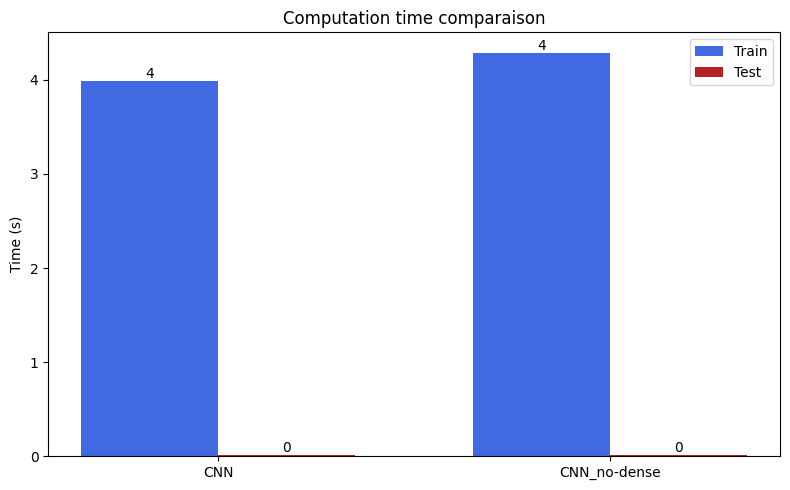

<Figure size 640x480 with 0 Axes>

In [35]:
### Time
train_times = [time_train_full, time_train_nodense_full] 
test_times = [time_test_grid_full, time_test_grid_nodense_full]

x = np.arange(len(methods))
width = 0.35

fig_time_full, ax = plt.subplots(figsize=(8, 5))
bar1 = ax.bar(x - width/2, train_times, width, label='Train', color='royalblue')
bar2 = ax.bar(x + width/2, test_times, width, label='Test', color='firebrick')

for rect in bar1 + bar2:
    height = rect.get_height()
    plt.text(rect.get_x() + rect.get_width() / 2.0, height, f'{height:.0f}', ha='center', va='bottom')

ax.set_xticks(x)
ax.set_xticklabels(methods)
ax.set_ylabel("Time (s)")
ax.set_title("Computation time comparaison")
ax.legend()

plt.tight_layout()
plt.show()

plt.savefig("myImagePDF.pdf", format="pdf", bbox_inches="tight")


In [36]:
import json
import os

all_loss_train = {"mask":all_loss_train_mask.tolist(),"full":all_loss_train_full.tolist(),"nodense_mask":all_loss_train_nodense_mask.tolist(),"nodense_full":all_loss_train_nodense_full.tolist()}
all_loss_test = {"mask":all_loss_test_mask.tolist(),"full":all_loss_test_full.tolist(),"nodense_mask":all_loss_test_nodense_mask.tolist(),"nodense_full":all_loss_test_nodense_full.tolist()}
path = f"results/CNN_comparaison-{n_train}ntrain-{n_test}ntest-{n_points}npoints"

os.mkdir(path)
with open(path+"/all_loss", 'w') as f:
    json.dump({'train':all_loss_train, 'test':all_loss_test}, f)

In [37]:
fig_box_train_mask.savefig(path+"/fig_box_train_mask.png", format="png", bbox_inches="tight")
fig_box_test_mask.savefig(path+"/fig_box_test_mask.png", format="png", bbox_inches="tight")
fig_time_mask.savefig(path+"/fig_time_mask.png", format="png", bbox_inches="tight")

fig_box_train_full.savefig(path+"/fig_box_train_full.png", format="png", bbox_inches="tight")
fig_box_test_full.savefig(path+"/fig_box_test_full.png", format="png", bbox_inches="tight")
fig_time_full.savefig(path+"/fig_time_full.png", format="png", bbox_inches="tight")

fig_train_mask.savefig(path+"/fig_train_mask.png", format="png", bbox_inches="tight")
fig_train_full.savefig(path+"/all_loss_train_full.png", format="png", bbox_inches="tight")
fig_train_nodense_mask.savefig(path+"/time_train_nodense_mask.png", format="png", bbox_inches="tight")
fig_train_nodense_full.savefig(path+"/all_loss_train_nodense_full.png", format="png", bbox_inches="tight")